# 02 · Selezione e baseline / Selection and baselines

**Input · IT:** Le 15 feature candidate del notebook 01 e `settings.json`.

**Output · IT:** 5–8 input ordinati, preprocessing training-only, K-Means/GMM e `results/baseline_comparison.csv`.

**Input · EN:** The 15 candidate features from Notebook 01 and `settings.json`.

**Output · EN:** 5–8 ordered inputs, training-only preprocessing, K-Means/GMM and `results/baseline_comparison.csv`.

**Prima di iniziare / Before starting:** [scaling e leakage / scaling and leakage](https://scikit-learn.org/stable/common_pitfalls.html), [K-Means](https://scikit-learn.org/stable/modules/clustering.html#k-means), [Gaussian mixtures](https://scikit-learn.org/stable/modules/mixture.html); unità diverse e ridondanza / different units and redundancy.

**Avvio / Start:** Jupyter dalla cartella del progetto; import di `core` dalla radice con `settings.json` / Jupyter from the project folder; import `core` from the root containing `settings.json`.


## A · Selezione e preprocessing / Selection and preprocessing

### 1. Dividere le date / Split the dates

**IT:** Dividete le feature dopo il warmup in training, validation e test con proporzioni 60/20/20. Restituite confini e conteggi ordinati, senza sovrapposizioni né shuffle.

**EN:** Split features after warmup into training, validation and test using 60/20/20 proportions. Return ordered boundaries and counts, with no overlaps or shuffling.


In [22]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# project_root per far girare il notebook su qualunque computer
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

settings = json.loads((project_root / "settings.json").read_text())

# Le 15 feature prodotte dal notebook 01
features = pd.read_csv(project_root / settings["paths"]["results"] / "features.csv",
                       index_col="date", parse_dates=True)
print("Feature caricate:", features.shape, "| dal", features.index[0].date(), "al", features.index[-1].date())

# Divisione cronologica 60/20/20 (dopo il warm-up, già tolto nel notebook 01)
from core.selection import dividi_date

confini = dividi_date(features, settings)
tab_split = pd.DataFrame(confini).T
tab_split["quota"] = (tab_split["n_obs"] / len(features)).round(3)
display(tab_split)

# Etichetta del blocco per ogni giorno, per i controlli
split = pd.Series(index=features.index, dtype="object")
for nome, b in confini.items():
    split.loc[b["start"]:b["end"]] = nome

print("Ogni giorno in un solo blocco:", split.notna().all(),
      "| totale:", tab_split["n_obs"].sum(), "=", len(features))
print("Blocchi in ordine, senza sovrapposizioni:",
      confini["train"]["end"] < confini["validation"]["start"]
      and confini["validation"]["end"] < confini["test"]["start"])
print("Ordine cronologico rispettato (niente shuffle):",
      (split.map({"train": 0, "validation": 1, "test": 2}).diff().dropna() >= 0).all())


# STILE DEL NOTEBOOK E TABELLE UNIFORMI

plt.rcParams.update({
    "figure.figsize": (12, 5),
    "figure.dpi": 120,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "legend.frameon": False,
    "font.family": "sans-serif"
})

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def taBella(df, precisione=3):
    return (
        df.style
        .format(precision=precisione)
        .set_properties(**{
            "text-align": "center",
            "padding": "7px"
        })
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("background-color", "#243447"),
                    ("color", "white"),
                    ("font-weight", "bold"),
                    ("text-align", "center"),
                    ("padding", "9px")
                ]
            },
            {
                "selector": "td",
                "props": [("border-bottom", "1px solid #dddddd")]
            }
        ])
    )

Feature caricate: (3617, 15) | dal 2005-11-16 al 2020-04-01


,start,end,n_obs,quota
train,2005-11-16,2014-07-02,2170,0.600
validation,2014-07-03,2017-05-16,723,0.200
test,2017-05-17,2020-04-01,724,0.200


Ogni giorno in un solo blocco: True | totale: 3617 = 3617
Blocchi in ordine, senza sovrapposizioni: True
Ordine cronologico rispettato (niente shuffle): True


### 2. Controllare la variabilità / Check variability

**IT:** Individuate feature costanti o inutilizzabili usando solo il training e criteri coerenti con le unità. Salvate le esclusioni e verificate che modificare validation o test non cambi il risultato.

**EN:** Identify constant or unusable features using training only and unit-aware criteria. Record exclusions and check that changing validation or test leaves the result unchanged.


In [23]:
from core.selection import controlla_variabilita

# Solo il training: fino all'ultima data del blocco train (inclusa)
fine_train = confini["train"]["end"]
report = controlla_variabilita(features, fine_train)
display(taBella(report.round(3)))

escluse = report.index[~report["utilizzabile"]].tolist()
print("Feature costanti:", report.index[report["costante"]].tolist())
print("Feature escluse (non persistenti):", escluse)
print("Feature utilizzabili:", report["utilizzabile"].sum(), "su", len(report))

# Salviamo le esclusioni con il motivo
tab_escluse = report.loc[escluse, ["dev_std", "autocorr_1g"]].copy()
tab_escluse["motivo"] = "non persistente: cambia a caso ogni giorno"
tab_escluse.to_csv(project_root / settings["paths"]["results"] / "feature_escluse.csv")
print("Esclusioni salvate in results/feature_escluse.csv")

# Controllo: sostituiamo validation e test con numeri casuali.
# Se il report usa solo il training, deve restare identico.
modificate = features.copy()
dopo_train = modificate.index > fine_train
modificate.loc[dopo_train] = np.random.default_rng(0).normal(size=(dopo_train.sum(), modificate.shape[1]))
report_mod = controlla_variabilita(modificate, fine_train)
print("Report identico cambiando validation e test:", report_mod.equals(report))

,media,dev_std,quota_valori_ripetuti,autocorr_1g,costante,persistente,utilizzabile
equity_return,0.000,0.014,0.003,-0.092,False,False,False
bond_return,0.000,0.009,0.004,-0.033,False,False,False
gold_return,0.001,0.013,0.006,-0.018,False,False,False
equity_volatility,0.174,0.129,0.000,0.994,False,True,True
bond_volatility,0.137,0.057,0.000,0.990,False,True,True
gold_volatility,0.197,0.084,0.000,0.984,False,True,True
equity_momentum,0.021,0.085,0.000,0.977,False,True,True
bond_momentum,0.017,0.069,0.000,0.980,False,True,True
gold_momentum,0.032,0.089,0.000,0.975,False,True,True
equity_drawdown,-0.074,0.111,0.148,0.996,False,True,True


Feature costanti: []
Feature escluse (non persistenti): ['equity_return', 'bond_return', 'gold_return']
Feature utilizzabili: 12 su 15
Esclusioni salvate in results/feature_escluse.csv
Report identico cambiando validation e test: True


### 3. Selezionare 5–8 input / Select 5–8 inputs

**IT:** Implementate `selection.select_features` restituendo 5–8 nomi ordinati, sulla base delle correlazioni e della ridondanza training. Conservate al massimo 2–3 sottoinsiemi candidati nei settings; non confrontate likelihood fra input diversi.

**EN:** Implement `selection.select_features` to return 5–8 ordered names based on training correlations and redundancy. Keep at most 2–3 candidate subsets in settings; do not compare likelihoods across different inputs.


Coppie più correlate nel training:


,,spearman,|spearman|
equity_volatility,equity_drawdown,-0.810,0.810
gold_momentum,gold_drawdown,0.680,0.680
equity_gold_correlation,bond_gold_correlation,-0.630,0.630
bond_momentum,bond_drawdown,0.610,0.610
equity_volatility,bond_volatility,0.610,0.610
equity_momentum,equity_drawdown,0.570,0.570
bond_volatility,equity_drawdown,-0.510,0.510
equity_volatility,equity_momentum,-0.500,0.500


Sottoinsieme principale (8 feature): ['equity_volatility', 'bond_volatility', 'gold_volatility', 'equity_momentum', 'bond_momentum', 'gold_momentum', 'equity_bond_correlation', 'equity_gold_correlation']
Sottoinsieme alternativo (7 feature): ['equity_volatility', 'gold_volatility', 'equity_momentum', 'bond_momentum', 'gold_momentum', 'equity_bond_correlation', 'equity_gold_correlation']
Differenza: ['bond_volatility']
Correlazione massima fra le feature scelte: 0.61


,Motivo esclusione
equity_return,non persistente (compito 2)
bond_return,non persistente (compito 2)
gold_return,non persistente (compito 2)
equity_drawdown,ridondante: |rho| = 0.81 con equity_volatility
bond_drawdown,oltre il massimo di 8 feature
gold_drawdown,oltre il massimo di 8 feature
bond_gold_correlation,oltre il massimo di 8 feature


,Feature,Selezione 0.7,Selezione 0.6
0,equity_return,False,False
1,bond_return,False,False
2,gold_return,False,False
3,equity_volatility,True,True
4,bond_volatility,True,False
5,gold_volatility,True,True
6,equity_momentum,True,True
7,bond_momentum,True,True
8,gold_momentum,True,True
9,equity_drawdown,False,False


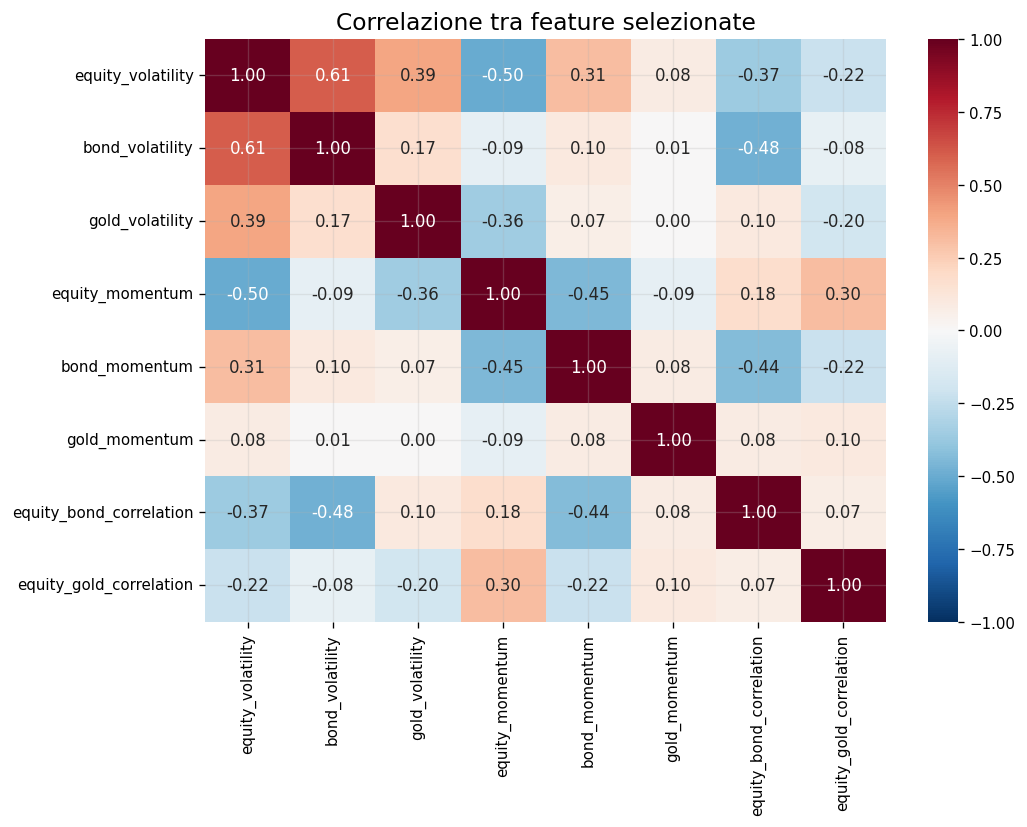

Stessa scelta cambiando validation e test: True


In [25]:
from core.selection import select_features

import copy
settings_selezione = copy.deepcopy(settings)
settings_selezione["selection"]["selected_features"] = []   # selezione da zero, non quella congelata

# Correlazioni di Spearman sul solo training: le coppie più ridondanti
corr_train = features.loc[:fine_train].corr(method="spearman")
coppie = corr_train.where(np.triu(np.ones(corr_train.shape, dtype=bool), k=1)).stack()
coppie = coppie.rename("spearman").to_frame()
coppie["|spearman|"] = coppie["spearman"].abs()
print("Coppie più correlate nel training:")
display(taBella(coppie.sort_values("|spearman|", ascending=False).head(8).round(2)))

# Sottoinsieme principale (soglia 0.7) e un alternativo più severo (soglia 0.6)
scelte = select_features(features, fine_train, settings_selezione)
alternativo = select_features(features, fine_train, settings_selezione, soglia_correlazione=0.6)
print(f"Sottoinsieme principale ({len(scelte)} feature):", scelte)
print(f"Sottoinsieme alternativo ({len(alternativo)} feature):", alternativo)
print("Differenza:", sorted(set(scelte) ^ set(alternativo)))

massima = corr_train.loc[scelte, scelte].abs().where(~np.eye(len(scelte), dtype=bool)).max().max()
print("Correlazione massima fra le feature scelte:", round(massima, 2))

# Perché le altre sono rimaste fuori
motivi = {}
for f in features.columns:
    if f in scelte:
        continue
    if f in escluse:
        motivi[f] = "non persistente (compito 2)"
    else:
        c = corr_train.loc[f, scelte].abs()
        if c.max() > 0.7:
            motivi[f] = f"ridondante: |rho| = {c.max():.2f} con {c.idxmax()}"
        else:
            motivi[f] = "oltre il massimo di 8 feature"
display(pd.DataFrame.from_dict(motivi, orient="index", columns=["Motivo esclusione"]))

confronto_feature = pd.DataFrame({
    "Feature": features.columns,
    "Selezione 0.7": [
        f in scelte for f in features.columns
    ],
    "Selezione 0.6": [
        f in alternativo for f in features.columns
    ]
})

display(confronto_feature)

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr_train.loc[scelte, scelte],
    annot=True,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlazione tra feature selezionate")
plt.tight_layout()
plt.show()

# Controllo: cambiando validation e test la scelta non deve cambiare
modificate = features.copy()
modificate.loc[modificate.index > fine_train] *= -3
print("Stessa scelta cambiando validation e test:", select_features(modificate, fine_train, settings_selezione) == scelte)

### 4. Standardizzare gli input / Scale the inputs

**IT:** Implementate `selection.prepare_model_data` adattando lo scaler soltanto al training. Restituite `feature_names`, `scaler`, `boundaries` e `scaled_blocks` datati (`train`, `validation`, `test`), controllando ordine e valori finiti.

**EN:** Implement `selection.prepare_model_data` by fitting the scaler on training only. Return `feature_names`, `scaler`, `boundaries` and dated `scaled_blocks` (`train`, `validation`, `test`), checking order and finite values.


In [26]:
from core.selection import prepare_model_data

prepared = prepare_model_data(features, scelte, settings)
blocchi = prepared["scaled_blocks"]

print("Chiavi restituite:", list(prepared.keys()))
print("Ordine delle feature conservato:", prepared["feature_names"] == scelte)
for nome, blocco in blocchi.items():
    print(f"{nome:<11} {blocco.shape} dal {blocco.index[0].date()} al {blocco.index[-1].date()}"
          f" | valori finiti: {np.isfinite(blocco.to_numpy()).all()}")

# Media e dev. std per blocco: nel training sono esattamente 0 e 1,
# negli altri blocchi no (lo scaler è quello del training)
riepilogo = pd.DataFrame({
    nome: {"media min": b.mean().min(), "media max": b.mean().max(),
           "dev.std min": b.std(ddof=0).min(), "dev.std max": b.std(ddof=0).max()}
    for nome, b in blocchi.items()
}).T
display(taBella(riepilogo.round(3)))

# I parametri dello scaler: media e dev. std del training, nelle unità originali
scaler = prepared["scaler"]
display(taBella(riepilogo.round(3)))
tab_scaler = pd.DataFrame(
    {
        "Media training": scaler.mean_,
        "Dev. standard training": scaler.scale_
    },
    index=scelte
)
display(taBella(tab_scaler.round(4)))

# Esempio: la volatilità SPY del 16/03/2020 (COVID) prima e dopo la standardizzazione
giorno = pd.Timestamp("2020-03-16")
print(f"Volatilità SPY il 16/03/2020: {features.loc[giorno, 'equity_volatility']:.2%} "
      f"-> {blocchi['test'].loc[giorno, 'equity_volatility']:.2f} deviazioni standard sopra la media del training")

# Controllo: cambiando validation e test lo scaler non deve cambiare
modificate = features.copy()
modificate.loc[modificate.index > fine_train] += 100
p2 = prepare_model_data(modificate, scelte, settings)
print("Scaler identico cambiando validation e test:",
      np.allclose(p2["scaler"].mean_, scaler.mean_) and np.allclose(p2["scaler"].scale_, scaler.scale_))

Chiavi restituite: ['feature_names', 'scaler', 'boundaries', 'scaled_blocks']
Ordine delle feature conservato: True
train       (2170, 8) dal 2005-11-16 al 2014-07-02 | valori finiti: True
validation  (723, 8) dal 2014-07-03 al 2017-05-16 | valori finiti: True
test        (724, 8) dal 2017-05-17 al 2020-04-01 | valori finiti: True


,media min,media max,dev.std min,dev.std max
train,-0.000,0.000,1.000,1.000
validation,-1.029,0.109,0.423,0.891
test,-1.062,0.120,0.526,1.257


,media min,media max,dev.std min,dev.std max
train,-0.000,0.000,1.000,1.000
validation,-1.029,0.109,0.423,0.891
test,-1.062,0.120,0.526,1.257


,Media training,Dev. standard training
equity_volatility,0.174,0.129
bond_volatility,0.137,0.057
gold_volatility,0.197,0.084
equity_momentum,0.021,0.085
bond_momentum,0.017,0.069
gold_momentum,0.032,0.089
equity_bond_correlation,-0.393,0.275
equity_gold_correlation,0.144,0.284


Volatilità SPY il 16/03/2020: 76.95% -> 4.63 deviazioni standard sopra la media del training
Scaler identico cambiando validation e test: True


### 5. Integrare il preprocessing / Integrate preprocessing

**IT:** Portate selezione e scaling in `core/selection.py`; lasciate la lista iniziale vuota finché la selezione non è conclusa. Verificate training-only, cronologia e trasformazioni identiche dopo salvataggio e ricaricamento dello scaler.

**EN:** Move selection and scaling into `core/selection.py`; keep the initial list empty until selection is complete. Check training-only fitting, chronology and identical transformations after saving and reloading the scaler.


In [5]:
import copy
import tempfile
import joblib

# 1) La lista nei settings è quella che si ottiene rifacendo la selezione da zero
dai_settings = settings["selection"]["selected_features"]
settings_vuoti = copy.deepcopy(settings)
settings_vuoti["selection"]["selected_features"] = []
ricalcolate = select_features(features, fine_train, settings_vuoti)
print("Feature nei settings:", dai_settings)
print("Coincidono con la selezione ricalcolata:", dai_settings == ricalcolate)
print("Sottoinsiemi candidati nei settings:", list(settings["selection"]["candidate_subsets"]))

# Da qui si usa la scelta congelata
scelte = select_features(features, fine_train, settings)
prepared = prepare_model_data(features, scelte, settings)
b = prepared["scaled_blocks"]

# 2) Cronologia
print("Indici crescenti e senza duplicati:",
      all(x.index.is_monotonic_increasing and x.index.is_unique for x in b.values()))
print("Train < validation < test:",
      b["train"].index[-1] < b["validation"].index[0] and b["validation"].index[-1] < b["test"].index[0])
print("Totale giorni:", sum(len(x) for x in b.values()), "=", len(features))

# 3) Scaler adattato solo sul training
print("Scaler = media e dev.std del solo training:",
      np.allclose(prepared["scaler"].mean_, features.loc[:fine_train, scelte].mean())
      and np.allclose(prepared["scaler"].scale_, features.loc[:fine_train, scelte].std(ddof=0)))

# 4) Salvare e ricaricare lo scaler: deve dare esattamente gli stessi numeri
with tempfile.TemporaryDirectory() as cartella:
    percorso = Path(cartella) / "scaler.joblib"
    joblib.dump(prepared["scaler"], percorso)
    ricaricato = joblib.load(percorso)
test_originale = features.loc[b["test"].index, scelte].to_numpy()
print("Trasformazione identica dopo il ricaricamento:",
      np.array_equal(ricaricato.transform(test_originale), b["test"].to_numpy()))

# 5) Un nome sbagliato nei settings deve dare errore
sbagliati = copy.deepcopy(settings)
sbagliati["selection"]["selected_features"] = ["equity_volatility", "feature_inventata"]
try:
    select_features(features, fine_train, sbagliati)
    print("PROBLEMA: nome sbagliato NON respinto")
except ValueError as errore:
    print(f"OK - nome sbagliato respinto -> {errore}")

Feature nei settings: ['equity_volatility', 'bond_volatility', 'gold_volatility', 'equity_momentum', 'bond_momentum', 'gold_momentum', 'equity_bond_correlation', 'equity_gold_correlation']
Coincidono con la selezione ricalcolata: True
Sottoinsiemi candidati nei settings: ['principale_soglia_0.7', 'alternativo_soglia_0.6']
Indici crescenti e senza duplicati: True
Train < validation < test: True
Totale giorni: 3617 = 3617
Scaler = media e dev.std del solo training: True
Trasformazione identica dopo il ricaricamento: True
OK - nome sbagliato respinto -> Feature nei settings che non esistono: ['feature_inventata']


## B · Baseline di clustering / Clustering baselines

### 6. Adattare K-Means / Fit K-Means

**IT:** Adattate K-Means agli input training scalati e applicate il modello fisso ai blocchi successivi. Restituite estimatore e label datate, controllando allineamento e ripetibilità con seed fisso.

**EN:** Fit K-Means on scaled training inputs and apply the frozen model to later blocks. Return the estimator and dated labels, checking alignment and repeatability with a fixed seed.


Label allineate alle date dei blocchi: True
Label del training = quelle trovate durante l'addestramento: True
Stesso seed -> stesse label: True
Quota di giorni per gruppo:


col_0,train,validation,test
kmeans_state,,,
0,0.402,0.264,0.345
1,0.504,0.736,0.628
2,0.094,0.000,0.026


Centri dei gruppi nelle unità originali:


,gruppo 0,gruppo 1,gruppo 2
equity_volatility,0.120,0.162,0.476
bond_volatility,0.109,0.139,0.247
gold_volatility,0.193,0.170,0.354
equity_momentum,0.055,0.026,-0.145
bond_momentum,-0.022,0.032,0.104
gold_momentum,0.031,0.027,0.058
equity_bond_correlation,-0.121,-0.580,-0.547
equity_gold_correlation,0.239,0.117,-0.117


Giorni nel gruppo più agitato, per anno:
date
2008    81
2009    65
2010     1
2011    58
2020    19
Name: count, dtype: int64


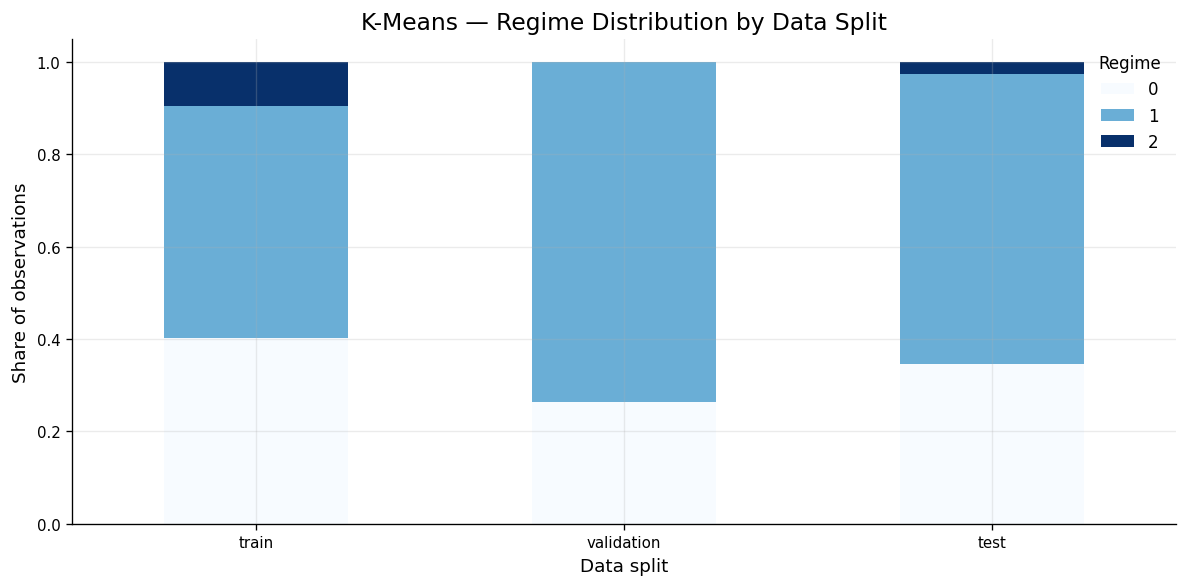

In [30]:
from core.models import adatta_kmeans

# Esempio con 3 gruppi e seed fisso (il numero di gruppi lo scegliamo al compito 8)
k, seed = 3, 42
kmeans, label_km = adatta_kmeans(prepared, k, seed)

# Allineamento: una label per ogni giorno dei tre blocchi, con le stesse date
date_attese = pd.concat([prepared["scaled_blocks"][b] for b in ["train", "validation", "test"]]).index
print("Label allineate alle date dei blocchi:", label_km.index.equals(date_attese))
print("Label del training = quelle trovate durante l'addestramento:",
      np.array_equal(label_km.loc[:fine_train].to_numpy(), kmeans.labels_))

# Ripetibilità: stesso seed, stesso risultato
_, label_bis = adatta_kmeans(prepared, k, seed)
print("Stesso seed -> stesse label:", label_km.equals(label_bis))

# Etichetta del blocco per ogni giorno
split = pd.Series(index=features.index, dtype="object")
for nome, b in prepared["boundaries"].items():
    split.loc[b["start"]:b["end"]] = nome

# Quota di giorni in ogni gruppo, per blocco
print("Quota di giorni per gruppo:")
quote_km = pd.crosstab(label_km, split, normalize="columns")[["train", "validation", "test"]]
display(taBella(quote_km))

# I centri riportati nelle unità originali (es. volatilità 0.12 = 12% annuo)
centri = pd.DataFrame(prepared["scaler"].inverse_transform(kmeans.cluster_centers_),
                      columns=scelte, index=[f"gruppo {i}" for i in range(k)])
print("Centri dei gruppi nelle unità originali:")
display(taBella(centri.T.round(3)))

# In quali anni cade il gruppo più agitato
print("Giorni nel gruppo più agitato, per anno:")
print(label_km[label_km == k - 1].index.year.value_counts().sort_index())

# Grafico di distribuzione K-Means
quote_km.T.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    colormap="Blues"
)

plt.title("K-Means — Regime Distribution by Data Split")
plt.xlabel("Data split")
plt.ylabel("Share of observations")
plt.legend(title="Regime")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 7. Adattare la GMM / Fit the GMM

**IT:** Adattate `GaussianMixture` diagonale agli stessi input e restituite estimatore, label e probabilità. Controllate convergenza, varianze positive e somme unitarie, registrando anche i fit falliti.

**EN:** Fit diagonal `GaussianMixture` on the same inputs and return the estimator, labels and probabilities. Check convergence, positive variances and unit row sums, recording failed fits too.


,Valore
k,3
seed,42
stato,ok
errore,
convergenza,True
iterazioni,23
varianza_minima,0.049


Convergenza raggiunta: True in 23 iterazioni
Varianze tutte positive: True | forma: (3, 8)
Probabilità: somma per riga = 1: True
Probabilità tra 0 e 1: True
Label = stato più probabile: True
Date allineate a K-Means: True
Stesso seed -> stesse probabilità: True
Quota di giorni per componente:


col_0,train,validation,test
gmm_state,,,
0,0.518,0.647,0.671
1,0.375,0.353,0.301
2,0.107,0.000,0.028


Confidenza (probabilità massima) per blocco:


,mean,min
test,0.942,0.506
train,0.920,0.501
validation,0.909,0.500


Giorni incerti (confidenza < 0.6): 162


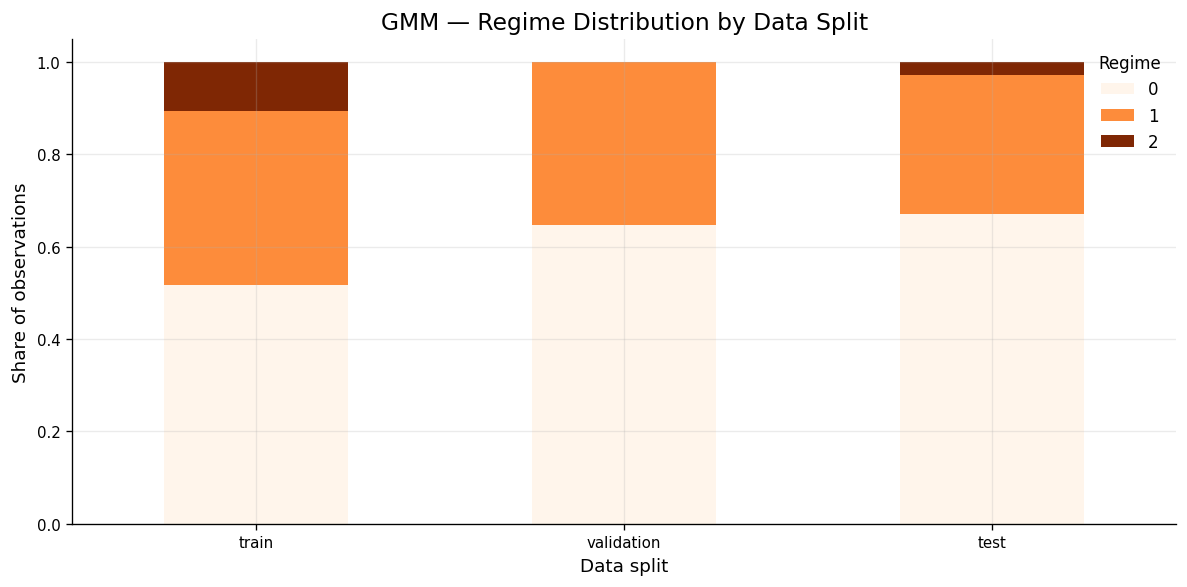

,componente 0,componente 1,componente 2
equity_volatility,0.104,0.187,0.455
bond_volatility,0.105,0.149,0.247
gold_volatility,0.177,0.183,0.334
equity_momentum,0.050,0.025,-0.120
bond_momentum,-0.004,0.022,0.097
gold_momentum,0.023,0.038,0.051
equity_bond_correlation,-0.266,-0.507,-0.566
equity_gold_correlation,0.195,0.150,-0.118


Righe = gruppo K-Means, colonne = componente GMM:


gmm_state,0,1,2
kmeans_state,,,
0,1035,278,0
1,1043,1003,34
2,0,6,218


,k,seed,stato,errore,convergenza,iterazioni,varianza_minima
0,2,7,ok,,True,8,0.116
1,2,21,ok,,True,8,0.116
2,2,42,ok,,True,9,0.116
3,3,7,ok,,True,6,0.042
4,3,21,ok,,True,23,0.049
5,3,42,ok,,True,23,0.049
6,4,7,ok,,True,7,0.042
7,4,21,ok,,True,7,0.042
8,4,42,ok,,True,7,0.042


In [31]:
from core.models import adatta_gmm

# GMM esplorativo:
# utilizziamo lo stesso k e seed di K-Means
# per un confronto a parità di configurazione.
# La configurazione definitiva di GMM sarà scelta
# successivamente tramite validation.
gmm, label_gmm, prob_gmm, info = adatta_gmm(prepared, k, seed, settings["baselines"]["gmm_covariance_type"])
display(taBella(pd.DataFrame(info, index=["Valore"]).T))

# Controlli richiesti dalla consegna
print("Convergenza raggiunta:", info["convergenza"], f"in {info['iterazioni']} iterazioni")
print("Varianze tutte positive:", (gmm.covariances_ > 0).all(), "| forma:", gmm.covariances_.shape)
print("Probabilità: somma per riga = 1:", np.allclose(prob_gmm.sum(axis=1), 1))
print("Probabilità tra 0 e 1:", ((prob_gmm >= 0) & (prob_gmm <= 1)).all().all())
print("Label = stato più probabile:", (label_gmm.to_numpy() == prob_gmm.to_numpy().argmax(axis=1)).all())
print("Date allineate a K-Means:", label_gmm.index.equals(label_km.index))

_, _, prob_bis, _ = adatta_gmm(prepared, k, seed)
print("Stesso seed -> stesse probabilità:", np.allclose(prob_bis, prob_gmm))

# Quota di giorni per componente, per blocco
print("Quota di giorni per componente:")
quote_gmm = pd.crosstab(label_gmm, split, normalize="columns")[["train", "validation", "test"]]
display(taBella(quote_gmm))

# Quanto è sicuro il modello: probabilità dello stato più probabile
confidenza = prob_gmm.max(axis=1)
print("Confidenza (probabilità massima) per blocco:")
display(taBella(confidenza.groupby(split).agg(["mean", "min"]).round(3)))
print("Giorni incerti (confidenza < 0.6):", (confidenza < 0.6).sum())

# Grafico di distribuzione GMM
quote_gmm.T.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    colormap="Oranges"
)

plt.title("GMM — Regime Distribution by Data Split")
plt.xlabel("Data split")
plt.ylabel("Share of observations")
plt.legend(title="Regime")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Centri nelle unità originali
centri_gmm = pd.DataFrame(prepared["scaler"].inverse_transform(gmm.means_),
                          columns=scelte, index=[f"componente {i}" for i in range(k)])
display(taBella(centri_gmm.T.round(3)))

# Confronto con K-Means: quanti giorni finiscono negli stessi gruppi
print("Righe = gruppo K-Means, colonne = componente GMM:")
display(taBella(pd.crosstab(label_km, label_gmm)))

# Registro di tutti i fit della griglia (2-4 componenti x 3 seed), compresi eventuali falliti
registro = [adatta_gmm(prepared, kk, sd)[3]
            for kk in settings["baselines"]["cluster_counts"]
            for sd in settings["baselines"]["seeds"]]
display(pd.DataFrame(registro))

### 8. Confrontare le baseline / Compare the baselines

**IT:** Confrontate i numeri di cluster configurati su training e validation, mantenendo input e date identici. Salvate occupazione, cambi di label e diagnostiche in `results/baseline_comparison.csv`, scegliendo i parametri senza il test.

**EN:** Compare configured cluster counts on training and validation, keeping inputs and dates identical. Save occupancy, label changes and diagnostics to `results/baseline_comparison.csv`, selecting parameters without test data.


In [33]:
from core.models import confronta_baseline

confronto = confronta_baseline(prepared, settings)

print("K-Means:")
colonne_km = ["k", "seed", "inerzia_train", "silhouette_validation", "quota_min_train",
              "quota_min_validation", "stati_vuoti_validation", "cambi_train", "cambi_validation",
              "miglior_seed", "scelto"]
display(confronto.loc[confronto["modello"] == "kmeans", colonne_km].round(3))

print("GMM:")
colonne_gmm = ["k", "seed", "convergenza", "loglik_train", "loglik_validation", "bic_validation",
               "quota_min_train", "quota_min_validation", "cambi_train", "cambi_validation",
               "miglior_seed", "scelto"]
display(confronto.loc[confronto["modello"] == "gmm", colonne_gmm].round(3))

for _, r in confronto[confronto["scelto"]].iterrows():
    print(f"Scelto {r['modello']}: k = {r['k']}, seed = {r['seed']}")

# Sintesi dei modelli selezionati
selezionati = confronto[confronto["scelto"]].copy()
riepilogo_modelli = selezionati[
    ["modello", "k", "seed", "quota_min_train",
     "quota_min_validation", "cambi_train", "cambi_validation"]
].copy()
riepilogo_modelli.columns = [
    "Modello", "Numero regimi", "Seed",
    "Quota minima train", "Quota minima validation",
    "Cambi train", "Cambi validation"
]
display(taBella(riepilogo_modelli.reset_index(drop=True)))

# Il test non è stato usato per nessuna scelta
print("Nessuna metrica calcolata sul test:", not any("test" in c for c in confronto.columns))

confronto.to_csv(project_root / settings["paths"]["results"] / "baseline_comparison.csv", index=False)
print("Salvato results/baseline_comparison.csv:", confronto.shape)

K-Means:


,k,seed,inerzia_train,silhouette_validation,quota_min_train,quota_min_validation,stati_vuoti_validation,cambi_train,cambi_validation,miglior_seed,scelto
0,2,7,"12,747.872",0.233,0.174,0.091,0,24,14,False,False
2,2,21,"12,747.847",0.231,0.176,0.094,0,26,14,True,False
4,2,42,"12,748.031",0.233,0.174,0.091,0,24,14,False,False
6,3,7,"10,941.259",0.295,0.094,0.000,1,43,22,True,True
8,3,21,"10,947.560",0.294,0.090,0.000,1,57,18,False,False
10,3,42,"10,941.259",0.295,0.094,0.000,1,43,22,False,False
12,4,7,"9,489.682",0.191,0.087,0.000,1,47,27,True,False
14,4,21,"9,489.682",0.191,0.087,0.000,1,47,27,False,False
16,4,42,"9,489.682",0.191,0.087,0.000,1,47,27,False,False


GMM:


,k,seed,convergenza,loglik_train,loglik_validation,bic_validation,quota_min_train,quota_min_validation,cambi_train,cambi_validation,miglior_seed,scelto
1,2,7,True,"-21,287.236","-6,675.267","13,567.787",0.240,0.124,42,12,False,False
3,2,21,True,"-21,287.236","-6,675.267","13,567.787",0.240,0.124,42,12,False,False
5,2,42,True,"-21,287.165","-6,675.061","13,567.374",0.241,0.124,40,12,True,True
7,3,7,True,"-20,419.259","-6,692.566","13,714.302",0.139,0.011,23,26,True,False
9,3,21,True,"-20,478.605","-6,369.589","13,068.349",0.107,0.000,78,24,False,False
11,3,42,True,"-20,478.613","-6,369.753","13,068.676",0.107,0.000,80,28,False,False
13,4,7,True,"-19,885.951","-6,673.262","13,787.613",0.115,0.000,59,32,False,False
15,4,21,True,"-19,885.951","-6,673.262","13,787.613",0.115,0.000,59,32,False,False
17,4,42,True,"-19,885.939","-6,673.294","13,787.676",0.115,0.000,59,32,True,False


Scelto gmm: k = 2, seed = 42
Scelto kmeans: k = 3, seed = 7


,Modello,Numero regimi,Seed,Quota minima train,Quota minima validation,Cambi train,Cambi validation
0,gmm,2,42,0.241,0.124,40,12
1,kmeans,3,7,0.094,0.000,43,22


Nessuna metrica calcolata sul test: True
Salvato results/baseline_comparison.csv: (18, 20)


### 9. Visualizzare i gruppi / Plot the groups

**IT:** Unite label datate e dati non scalati per produrre profili e timeline. Controllate conteggi, unità e join; i numeri dei cluster non identificano gruppi equivalenti fra modelli.

**EN:** Join dated labels to unscaled data to produce profiles and timelines. Check counts, units and joins; cluster numbers do not identify equivalent groups across models.


K-Means (k=3, seed=7) - profili sul training:


gruppo,0,1,2
giorni,872.000,1093.000,205.000
quota (%),40.180,50.370,9.450
rend. SPY ann. (%),19.060,11.870,-40.080
rend. TLT ann. (%),-1.960,9.840,34.880
rend. GLD ann. (%),10.930,13.630,28.690
vol. SPY (%),11.950,16.160,47.650
vol. TLT (%),10.900,13.940,24.660
vol. GLD (%),19.270,17.030,35.350
drawdown SPY (%),-3.510,-6.100,-30.830
corr. SPY-TLT,-0.120,-0.580,-0.550


GMM (k=2, seed=42) - profili sul training:


gruppo,0,1
giorni,1648.000,522.000
quota (%),75.940,24.060
rend. SPY ann. (%),14.480,-4.760
rend. TLT ann. (%),5.560,13.490
rend. GLD ann. (%),16.350,6.470
vol. SPY (%),12.400,33.360
vol. TLT (%),11.750,19.970
vol. GLD (%),17.390,26.820
drawdown SPY (%),-3.040,-21.160
corr. SPY-TLT,-0.340,-0.570


Righe = gruppo K-Means, colonne = gruppo GMM (stessi giorni):


gmm_state,0,1
kmeans_state,,
0,1282,31
1,1647,433
2,0,224


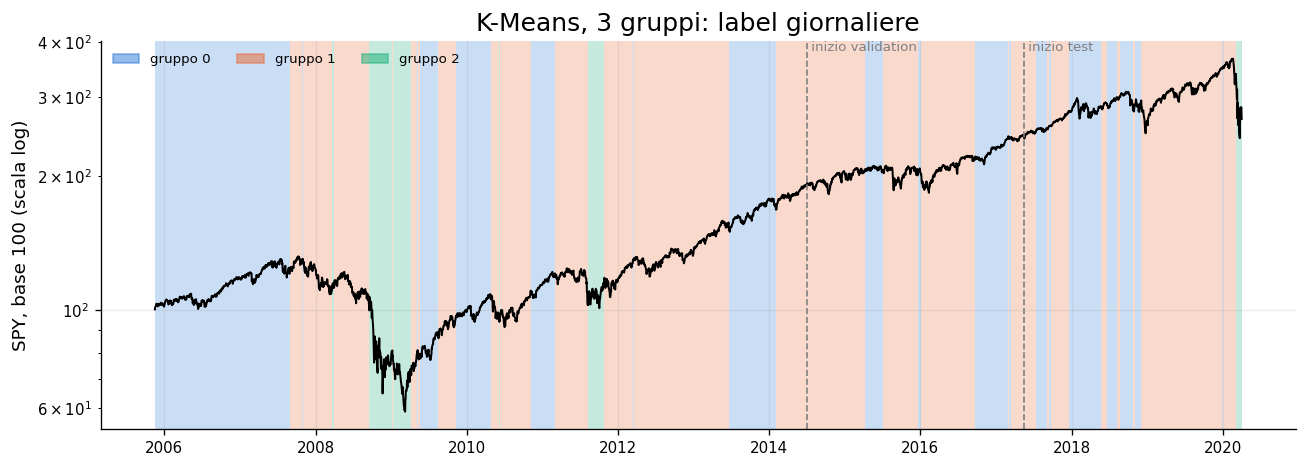

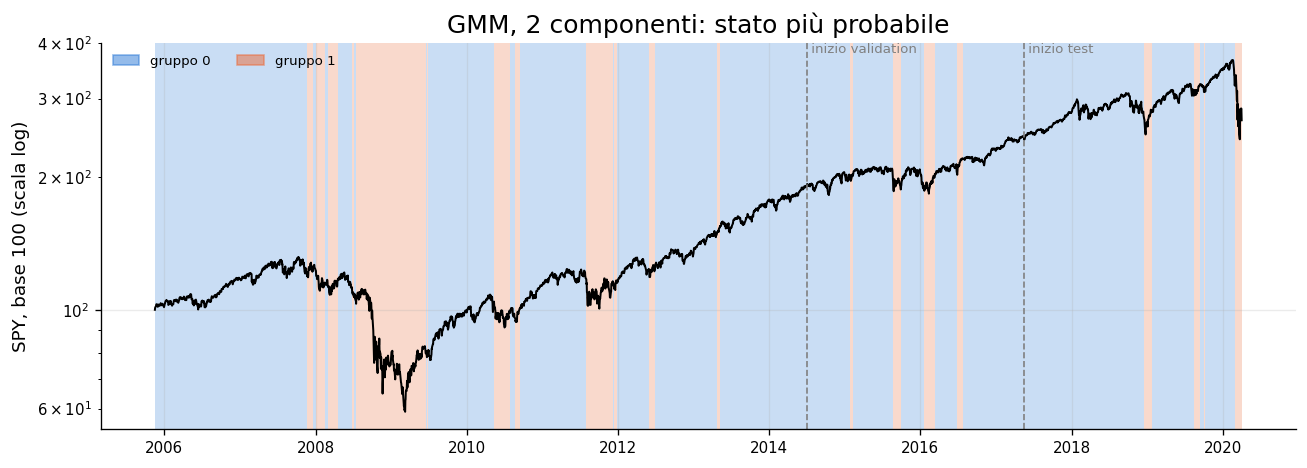


DURATA REGIMI - TRAIN
K-MEANS


,numero_periodi,durata_media,durata_mediana,durata_massima
kmeans_state,,,,
0,15,58.133,6.000,449
1,22,49.682,24.000,164
2,7,29.286,6.000,76


GMM


,numero_periodi,durata_media,durata_mediana,durata_massima
gmm_state,,,,
0,21,78.476,6.000,507
1,20,26.100,5.500,236



DURATA REGIMI - VALIDATION
K-MEANS


,numero_periodi,durata_media,durata_mediana,durata_massima
kmeans_state,,,,
0,11,17.364,1.000,111
1,12,44.333,6.500,178


... (2 outputs left out)


DURATA REGIMI - TEST
K-MEANS


,numero_periodi,durata_media,durata_mediana,durata_massima
kmeans_state,,,,
0,13,19.231,13.000,90
1,14,32.500,8.500,249
2,1,19.000,19.000,19


GMM


,numero_periodi,durata_media,durata_mediana,durata_massima
gmm_state,,,,
0,4,162.000,117.500,398
1,4,19.000,22.000,27


In [ ]:
from core.plots import grafico_timeline_gruppi

# Modelli scelti al compito 8
sel = confronto[confronto["scelto"]].set_index("modello")
k_km, seed_km = int(sel.loc["kmeans", "k"]), int(sel.loc["kmeans", "seed"])
k_gmm, seed_gmm = int(sel.loc["gmm", "k"]), int(sel.loc["gmm", "seed"])
kmeans, label_km = adatta_kmeans(prepared, k_km, seed_km)
gmm, label_gmm, prob_gmm, _ = adatta_gmm(prepared, k_gmm, seed_gmm)

def profilo(label, blocco="train"):
    """Medie per gruppo delle feature NON standardizzate, nelle unità originali."""
    dati = features.join(label.rename("gruppo"), how="inner")   # unione sulle date
    dati = dati[split.loc[dati.index] == blocco]
    g = dati.groupby("gruppo")
    tab = pd.DataFrame({
        "giorni": g.size(),
        "quota (%)": g.size() / len(dati) * 100,
        "rend. SPY ann. (%)": g["equity_return"].mean() * 252 * 100,
        "rend. TLT ann. (%)": g["bond_return"].mean() * 252 * 100,
        "rend. GLD ann. (%)": g["gold_return"].mean() * 252 * 100,
        "vol. SPY (%)": g["equity_volatility"].mean() * 100,
        "vol. TLT (%)": g["bond_volatility"].mean() * 100,
        "vol. GLD (%)": g["gold_volatility"].mean() * 100,
        "drawdown SPY (%)": g["equity_drawdown"].mean() * 100,
        "corr. SPY-TLT": g["equity_bond_correlation"].mean(),
        "corr. SPY-GLD": g["equity_gold_correlation"].mean(),
    })
    # controllo dell'unione: ogni giorno del blocco è contato una e una sola volta
    assert tab["giorni"].sum() == (split == blocco).sum(), "Unione sbagliata: giorni persi o doppi"
    return tab

print(f"K-Means (k={k_km}, seed={seed_km}) - profili sul training:")
tab_profilo_km = profilo(label_km).round(2)
display(taBella(tab_profilo_km.T))

print(f"GMM (k={k_gmm}, seed={seed_gmm}) - profili sul training:")
tab_profilo_gmm = profilo(label_gmm).round(2)
display(taBella(tab_profilo_gmm.T))
# I profili descrivono il comportamento medio degli asset nei diversi regimi. 
# Volatilità e drawdown aiutano a identificare condizioni di maggiore rischio, 
# mentre rendimenti e correlazioni permettono di caratterizzare il comportamento relativo delle asset class.
# I numeri dei cluster sono identificativi interni al modello: 
# il regime 0 di K-Means non corrisponde necessariamente al regime 0 di GMM.


# Stesso numero non vuol dire stesso gruppo: confronto giorno per giorno
print("Righe = gruppo K-Means, colonne = gruppo GMM (stessi giorni):")
display(pd.crosstab(label_km, label_gmm))

# Timeline: SPY ricostruito dai rendimenti giornalieri, base 100
plt.rcParams.update({
    "figure.figsize": (14, 5),
    "axes.titlesize": 15,
    "axes.labelsize": 11
})
spy = (1 + features["equity_return"]).cumprod() * 100
grafico_timeline_gruppi(spy, label_km, f"K-Means, {k_km} gruppi: label giornaliere", prepared["boundaries"])
plt.tight_layout()
plt.show()
grafico_timeline_gruppi(spy, label_gmm, f"GMM, {k_gmm} componenti: stato più probabile", prepared["boundaries"])
plt.tight_layout()
plt.show()

def durata_regimi(labels):
    cambi = labels.ne(labels.shift()).cumsum()
    durate = (
        labels.groupby(cambi)
        .size()
        .groupby(labels.groupby(cambi).first())
        .agg(["count", "mean", "median", "max"])
    )
    return durate.rename(columns={
        "count": "numero_periodi",
        "mean": "durata_media",
        "median": "durata_mediana",
        "max": "durata_massima"
    })

for blocco in ["train", "validation", "test"]:
    indice = prepared["scaled_blocks"][blocco].index
    print(f"\nDURATA REGIMI - {blocco.upper()}")
    print("K-MEANS")
    display(
        durata_regimi(label_km.loc[indice])
    )
    print("GMM")
    display(
        durata_regimi(label_gmm.loc[indice])
    )

### 10. Integrare le baseline / Integrate the baselines

**IT:** Implementate `models.fit_baselines` in `core/models.py` e riutilizzate i grafici di `core/plots.py`. Verificate che i modelli ricaricati riproducano label e probabilità senza nuovo fitting.

**EN:** Implement `models.fit_baselines` in `core/models.py` and reuse charts from `core/plots.py`. Check that reloaded models reproduce labels and probabilities without refitting.


Chiavi: ['kmeans', 'gmm', 'kmeans_labels', 'gmm_labels', 'gmm_probabilities', 'comparison', 'feature_names']
K-Means: 3 gruppi | GMM: 2 componenti
Stesse label del compito 9: True


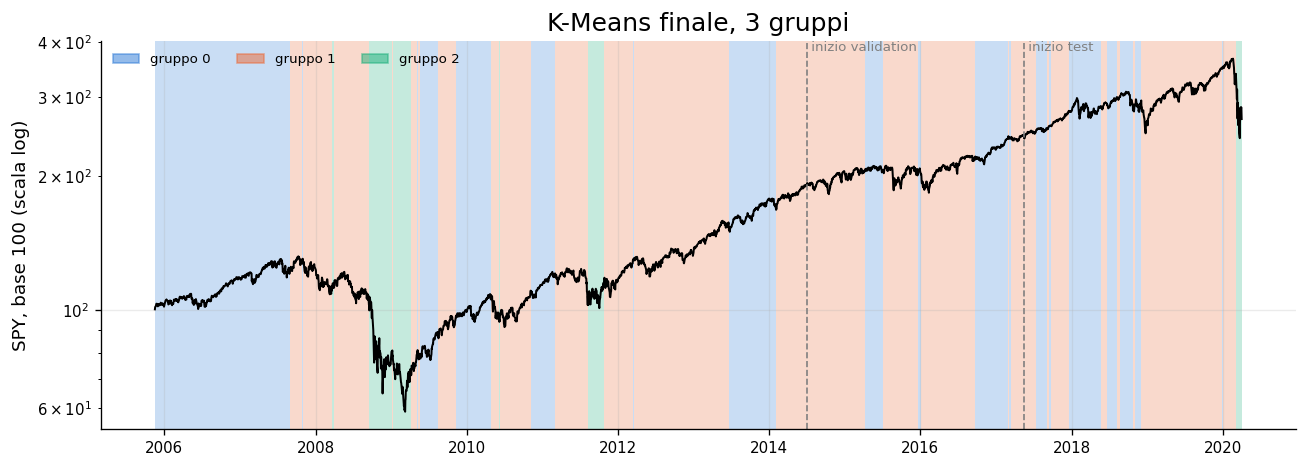

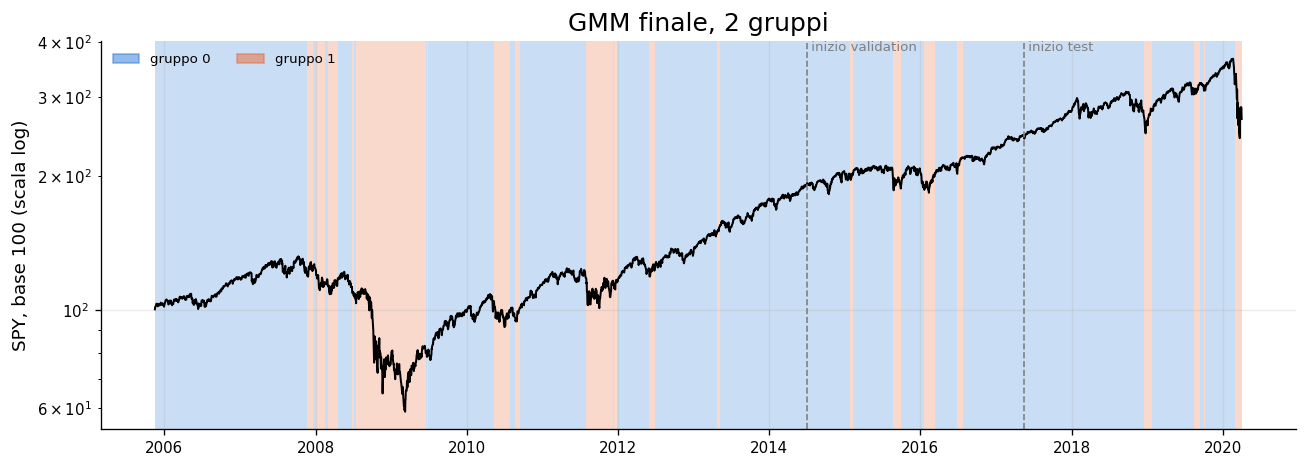

Stesse feature nello stesso ordine: True
K-Means ricaricato -> stesse label: True
GMM ricaricata -> stesse probabilità: True
GMM ricaricata -> stesse label: True
Iterazioni GMM invariate (nessun nuovo fit): True
FINAL BASELINE SUMMARY
K-Means: 3 regimi
GMM: 2 componenti
Label riproducibili: True


In [37]:
import tempfile
import joblib
from core.models import fit_baselines

# Tutto in un passaggio: confronto, scelta e modelli finali
baseline = fit_baselines(prepared, settings)
print("Chiavi:", list(baseline.keys()))
print("K-Means:", baseline["kmeans"].n_clusters, "gruppi | GMM:", baseline["gmm"].n_components, "componenti")
print("Stesse label del compito 9:",
      baseline["kmeans_labels"].equals(label_km) and baseline["gmm_labels"].equals(label_gmm))

# Salvare modelli + scaler + ordine delle feature, poi ricaricarli
with tempfile.TemporaryDirectory() as cartella:
    percorso = Path(cartella) / "baseline.joblib"
    joblib.dump({"kmeans": baseline["kmeans"], "gmm": baseline["gmm"],
                 "scaler": prepared["scaler"], "feature_names": prepared["feature_names"]}, percorso)
    ricaricato = joblib.load(percorso)

# Rifare le previsioni partendo dalle feature originali, solo con gli oggetti ricaricati
date = baseline["kmeans_labels"].index
x_tutti = ricaricato["scaler"].transform(features.loc[date, ricaricato["feature_names"]].to_numpy())

# Grafico riusato da core/plots.py, con i risultati di fit_baselines
grafico_timeline_gruppi(spy, baseline["kmeans_labels"], f"K-Means finale, {baseline['kmeans'].n_clusters} gruppi", prepared["boundaries"])
plt.tight_layout()
plt.show()

grafico_timeline_gruppi(spy, baseline["gmm_labels"], f"GMM finale, {baseline['gmm'].n_components} gruppi", prepared["boundaries"])
plt.tight_layout()
plt.show()

print("Stesse feature nello stesso ordine:", ricaricato["feature_names"] == scelte)
print("K-Means ricaricato -> stesse label:",
      np.array_equal(ricaricato["kmeans"].predict(x_tutti), baseline["kmeans_labels"].to_numpy()))
print("GMM ricaricata -> stesse probabilità:",
      np.allclose(ricaricato["gmm"].predict_proba(x_tutti), baseline["gmm_probabilities"].to_numpy(),
                  rtol=0, atol=1e-12))
print("GMM ricaricata -> stesse label:",
      np.array_equal(ricaricato["gmm"].predict_proba(x_tutti).argmax(axis=1), baseline["gmm_labels"].to_numpy()))
print("Iterazioni GMM invariate (nessun nuovo fit):", ricaricato["gmm"].n_iter_ == baseline["gmm"].n_iter_)

print("=" * 55)
print("FINAL BASELINE SUMMARY")
print("=" * 55)

print(f"K-Means: {baseline['kmeans'].n_clusters} regimi")
print(f"GMM: {baseline['gmm'].n_components} componenti")

print(
    "Label riproducibili:",
    baseline["kmeans_labels"].equals(label_km)
    and baseline["gmm_labels"].equals(label_gmm)
)

print("=" * 55)